In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("../data/raw/cardekho_dataset.csv")

In [5]:
print("List of all the columns:\n",df.columns.tolist())

List of all the columns:
 ['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']


# Remove the unnecessary column

In [6]:
df = df.drop(columns=["Unnamed: 0"])

In [7]:
print("Columns: ", df.columns)

Columns:  Index(['car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats', 'selling_price'],
      dtype='str')


# Categorial Features

In [46]:
print("Brand of car and its count:\n", df["brand"].value_counts())

Brand of car and its count:
 brand
Maruti           4992
Hyundai          2982
Honda            1485
Mahindra         1011
Toyota            793
Ford              790
Volkswagen        620
Renault           536
BMW               439
Tata              430
Mercedes-Benz     337
Skoda             334
Audi              192
Datsun            170
Jaguar             59
Land Rover         51
Jeep               41
Kia                32
Porsche            21
Volvo              20
MG                 19
Mini               17
Nissan             11
Lexus              10
Isuzu               8
Bentley             3
Maserati            2
ISUZU               2
Ferrari             1
Mercedes-AMG        1
Rolls-Royce         1
Force               1
Name: count, dtype: int64


In [41]:
print("Fuel Type of car and its count:\n", df["fuel_type"].value_counts())

Fuel Type of car and its count:
 fuel_type
Petrol      7643
Diesel      7419
CNG          301
LPG           44
Electric       4
Name: count, dtype: int64


In [42]:
print("Seller Type of car and its count :\n", df["seller_type"].value_counts())

Seller Type of car and its count :
 seller_type
Dealer              9539
Individual          5699
Trustmark Dealer     173
Name: count, dtype: int64


In [43]:
print("Transmission Type of car and its count:\n", df["transmission_type"].value_counts())

Transmission Type of car and its count:
 transmission_type
Manual       12225
Automatic     3186
Name: count, dtype: int64


In [18]:
df.describe()

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


# Univariate Analysis

Vehicle Age Distribution

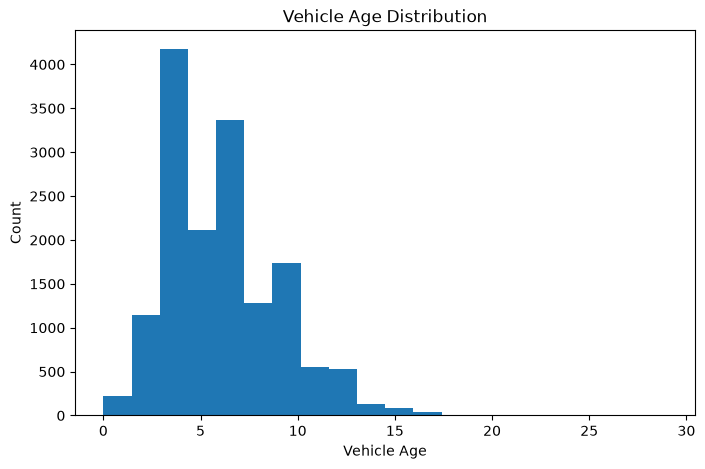

In [29]:
plt.figure(figsize=(8,5))
plt.hist(df["vehicle_age"], bins=20)
plt.title("Vehicle Age Distribution")
plt.xlabel("Vehicle Age")
plt.ylabel("Count")
plt.show()

Selling Price Distribution

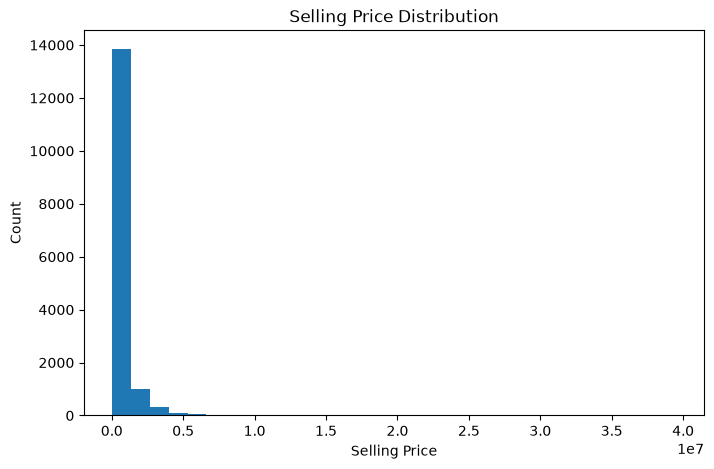

In [33]:
plt.figure(figsize=(8,5))
plt.hist(df["selling_price"], bins=30)
plt.title("Selling Price Distribution")
plt.xlabel("Selling Price")
plt.ylabel("Count")
plt.show()

Kilometer Driven Distribution

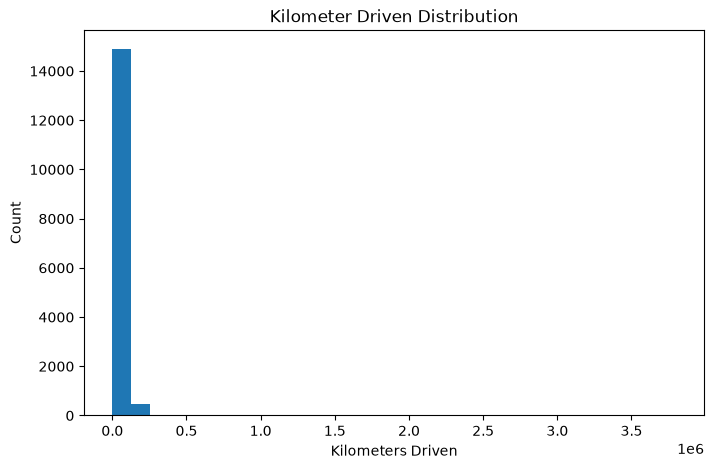

In [31]:
plt.figure(figsize=(8,5))
plt.hist(df["km_driven"], bins=30)
plt.title("Kilometer Driven Distribution")
plt.xlabel("Kilometers Driven")
plt.ylabel("Count")
plt.show()

In [55]:
df.nlargest(20, "km_driven")[
    ["car_name", "brand", "model", "vehicle_age", "km_driven", "selling_price"]
]

,car_name,brand,model,vehicle_age,km_driven,selling_price
15409,Mahindra XUV500,Mahindra,XUV500,5,3800000,1225000
11903,Mercedes-Benz E-Class,Mercedes-Benz,E-Class,9,1325000,1350000
8772,Toyota Innova,Toyota,Innova,6,950000,950000
4532,Renault Duster,Renault,Duster,4,850000,850000
6712,Volkswagen Vento,Volkswagen,Vento,9,830000,380000
10838,Hyundai Creta,Hyundai,Creta,6,825000,825000
11615,Volkswagen Polo,Volkswagen,Polo,5,820000,695000
7323,Ford Ecosport,Ford,Ecosport,6,720000,675000
9170,Skoda Rapid,Skoda,Rapid,5,675000,675000
7534,Toyota Fortuner,Toyota,Fortuner,2,590000,2850000


In [56]:
df["km_driven"].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
)

0.250     30000.0
0.500     50000.0
0.750     70000.0
0.900     98000.0
0.950    120000.0
0.990    180000.0
0.999    479590.0
Name: km_driven, dtype: float64

Investigate high-KM cars

In [14]:
high_km = df[df["km_driven"] > 200000]

print("Cars above 200,000 km:", len(high_km))
print("Percentage:", len(high_km) / len(df) * 100)

Cars above 200,000 km: 86
Percentage: 0.5580429563298943


In [17]:
high_km[
    ["car_name", "brand", "model", "vehicle_age", "km_driven", "selling_price"]
].sort_values("km_driven", ascending=False)

,car_name,brand,model,vehicle_age,km_driven,selling_price
15409,Mahindra XUV500,Mahindra,XUV500,5,3800000,1225000
11903,Mercedes-Benz E-Class,Mercedes-Benz,E-Class,9,1325000,1350000
8772,Toyota Innova,Toyota,Innova,6,950000,950000
4532,Renault Duster,Renault,Duster,4,850000,850000
6712,Volkswagen Vento,Volkswagen,Vento,9,830000,380000
...,...,...,...,...,...,...
4257,Mahindra Scorpio,Mahindra,Scorpio,8,209000,700000
3622,Maruti Swift Dzire,Maruti,Swift Dzire,8,208000,360000
394,Honda Amaze,Honda,Amaze,8,208000,300000
8472,Mahindra Scorpio,Mahindra,Scorpio,10,205000,460000


# Categorial Analysis

Brand Frequency

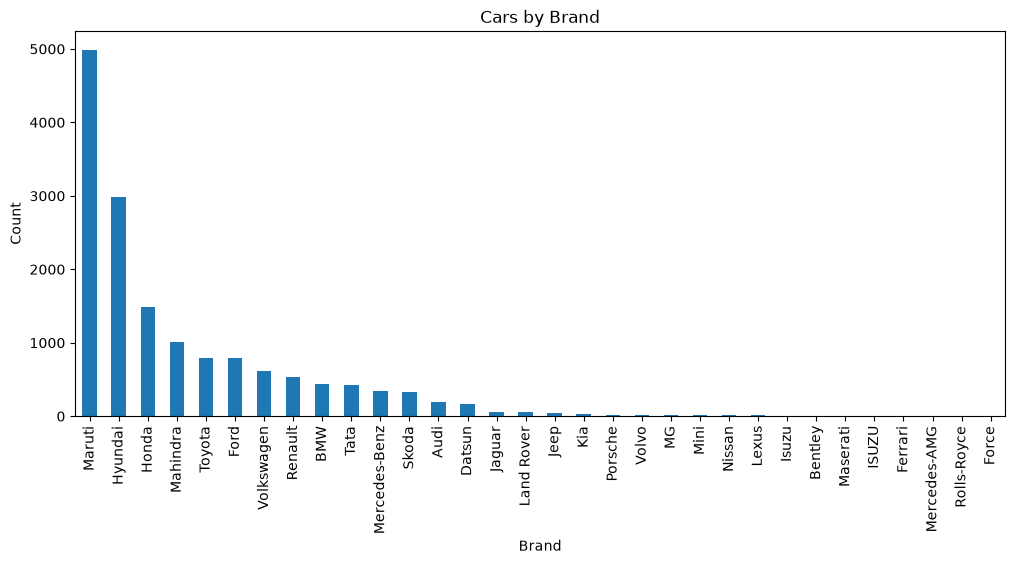

In [35]:
df["brand"].value_counts().plot(kind="bar", figsize=(12,5))
plt.title("Cars by Brand")
plt.xlabel("Brand")
plt.ylabel("Count")
plt.show()

In [13]:
df.groupby("brand")["selling_price"].agg(
    ["count", "mean", "median"]
).sort_values("median", ascending=False)

,count,mean,median
brand,,,
Ferrari,1,3.950000e+07,39500000.0
Rolls-Royce,1,2.420000e+07,24200000.0
Bentley,3,9.266667e+06,8100000.0
Maserati,2,6.100000e+06,6100000.0
Mercedes-AMG,1,5.100000e+06,5100000.0
Porsche,21,5.161190e+06,5000000.0
Lexus,10,5.146500e+06,4600000.0
Volvo,20,3.729700e+06,3750000.0
Land Rover,51,3.823902e+06,3400000.0


Fuel Type

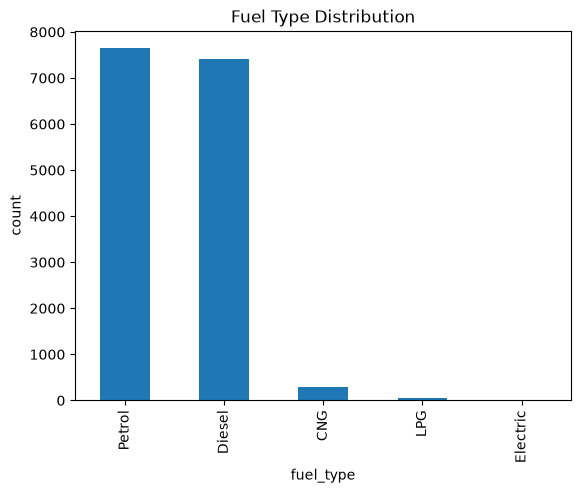

In [8]:
df["fuel_type"].value_counts().plot(kind="bar")
plt.title("Fuel Type Distribution")
plt.ylabel('count')
plt.show()

In [11]:
df.groupby("fuel_type")["selling_price"].agg(
    ["count", "mean", "median"]
).sort_values("median", ascending=False)

,count,mean,median
fuel_type,,,
Electric,4,1.853500e+06,1857500.0
Diesel,7419,1.000469e+06,700000.0
Petrol,7643,5.728619e+05,460000.0
CNG,301,4.176877e+05,370000.0
LPG,44,2.062727e+05,182500.0


Transmission Type

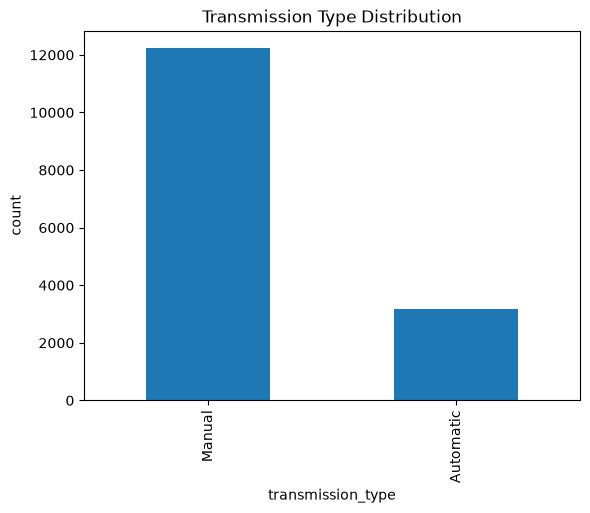

In [9]:
df["transmission_type"].value_counts().plot(kind="bar")
plt.title("Transmission Type Distribution")
plt.ylabel('count')
plt.show()

In [12]:
df.groupby("transmission_type")["selling_price"].agg(
    ["count", "mean", "median"]
).sort_values("median", ascending=False)

,count,mean,median
transmission_type,,,
Automatic,3186,1.579557e+06,1057000.0
Manual,12225,5.652852e+05,500000.0


# Bivariate Analysis

Vehicle Age Vs Selling Age

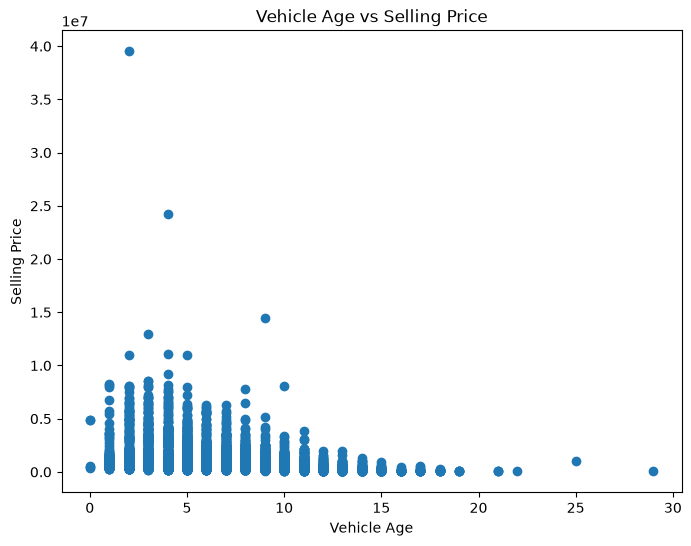

In [38]:
plt.figure(figsize=(8,6))
plt.scatter(df["vehicle_age"], df["selling_price"])
plt.xlabel("Vehicle Age")
plt.ylabel("Selling Price")
plt.title("Vehicle Age vs Selling Price")
plt.show()

Kilometers Driven Vs Selling Price

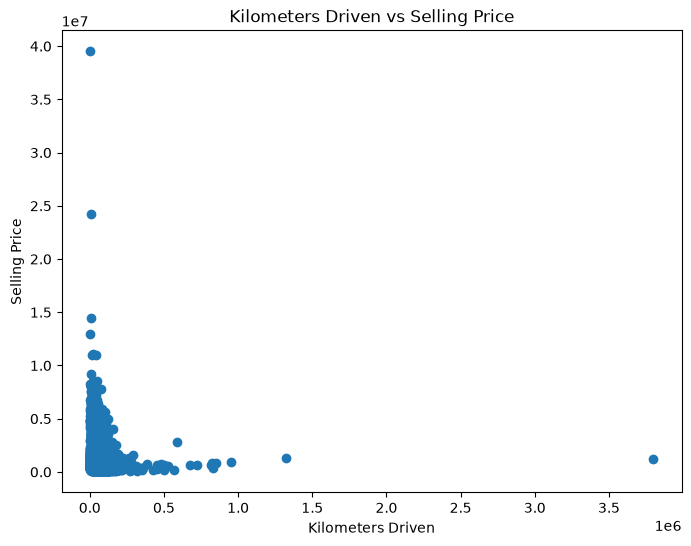

In [39]:
plt.figure(figsize=(8,6))
plt.scatter(df["km_driven"], df["selling_price"])
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price")
plt.title("Kilometers Driven vs Selling Price")
plt.show()

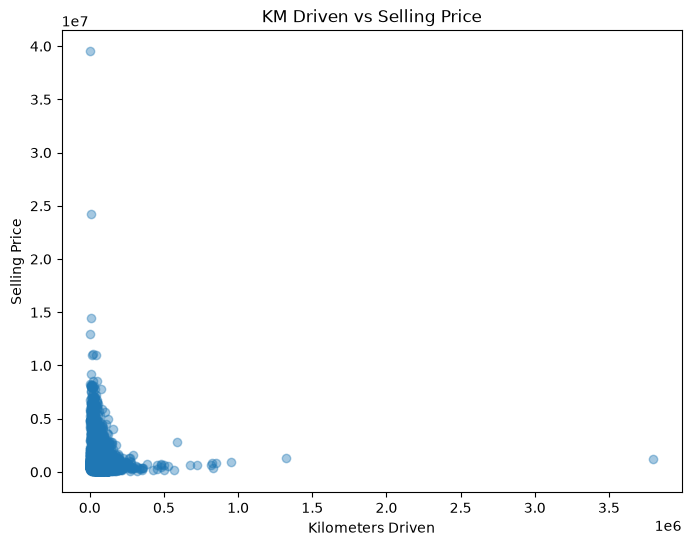

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["km_driven"],
    df["selling_price"],
    alpha=0.4
)

plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price")
plt.title("KM Driven vs Selling Price")

plt.show()

# Boxplots

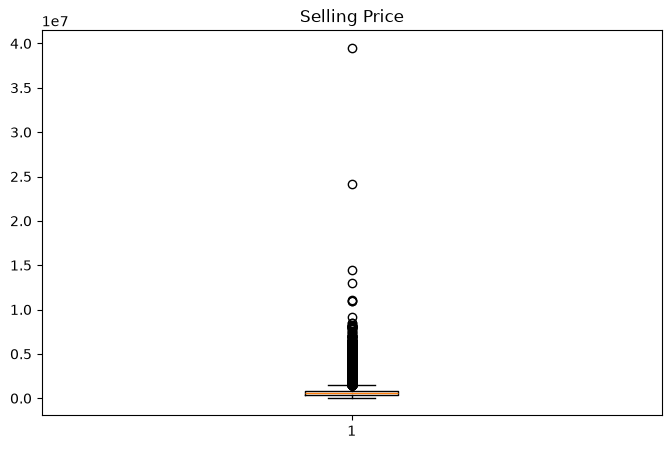

In [40]:
plt.figure(figsize=(8,5))
plt.boxplot(df["selling_price"])
plt.title("Selling Price")
plt.show()

In [54]:
print("Highest priced cars:\n", 
df.nlargest(10, "selling_price")[["car_name", "brand", "model", "vehicle_age", "selling_price"]])

Highest priced cars:
                     car_name          brand        model  vehicle_age  \
3799       Ferrari GTC4Lusso        Ferrari    GTC4Lusso            2   
10969      Rolls-Royce Ghost    Rolls-Royce        Ghost            4   
1172     Bentley Continental        Bentley  Continental            9   
9722   Mercedes-Benz S-Class  Mercedes-Benz      S-Class            3   
9364         Porsche Cayenne        Porsche      Cayenne            4   
1888   Mercedes-Benz S-Class  Mercedes-Benz      S-Class            5   
10989  Mercedes-Benz S-Class  Mercedes-Benz      S-Class            2   
11000       Land Rover Rover     Land Rover        Rover            4   
3096                   BMW 7            BMW            7            3   
8439                   BMW 7            BMW            7            3   

       selling_price  
3799        39500000  
10969       24200000  
1172        14500000  
9722        13000000  
9364        11100000  
1888        11000000  
10989       1

In [52]:
print("Lowest priced cars:\n",
df.nsmallest(10, "selling_price")[["car_name", "brand", "model", "vehicle_age", "selling_price"]])

Lowest priced cars:
              car_name    brand    model  vehicle_age  selling_price
7607   Maruti Wagon R   Maruti  Wagon R           21          40000
13676     Maruti Alto   Maruti     Alto           17          45000
3787      Maruti Alto   Maruti     Alto           19          50000
7361       Honda City    Honda     City           19          50000
12298  Maruti Wagon R   Maruti  Wagon R           17          50000
7930   Maruti Wagon R   Maruti  Wagon R           15          55000
2596      Maruti Alto   Maruti     Alto           29          60000
2966      Maruti Alto   Maruti     Alto           15          60000
9045   Hyundai Santro  Hyundai   Santro           14          60000
11190   Maruti Baleno   Maruti   Baleno           15          60000


In [53]:
print("Price percentile:\n",
df["selling_price"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

Price percentile:
 0.25     385000.0
0.50     556000.0
0.75     825000.0
0.90    1375000.0
0.95    2050000.0
0.99    4545000.0
Name: selling_price, dtype: float64


Calculate Numerical Correlation Matrix

In [15]:
df[["vehicle_age", "km_driven", "mileage", "engine", "max_power", "seats", "selling_price"]].corr()

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
vehicle_age,1.000000,0.333891,-0.257394,0.098965,0.005208,0.030791,-0.241851
km_driven,0.333891,1.000000,-0.105239,0.192885,0.044421,0.192830,-0.080030
mileage,-0.257394,-0.105239,1.000000,-0.632987,-0.533128,-0.440280,-0.305549
engine,0.098965,0.192885,-0.632987,1.000000,0.807368,0.551236,0.585844
max_power,0.005208,0.044421,-0.533128,0.807368,1.000000,0.172257,0.750236
seats,0.030791,0.192830,-0.440280,0.551236,0.172257,1.000000,0.115033
selling_price,-0.241851,-0.080030,-0.305549,0.585844,0.750236,0.115033,1.000000


# Correlation HeatMap

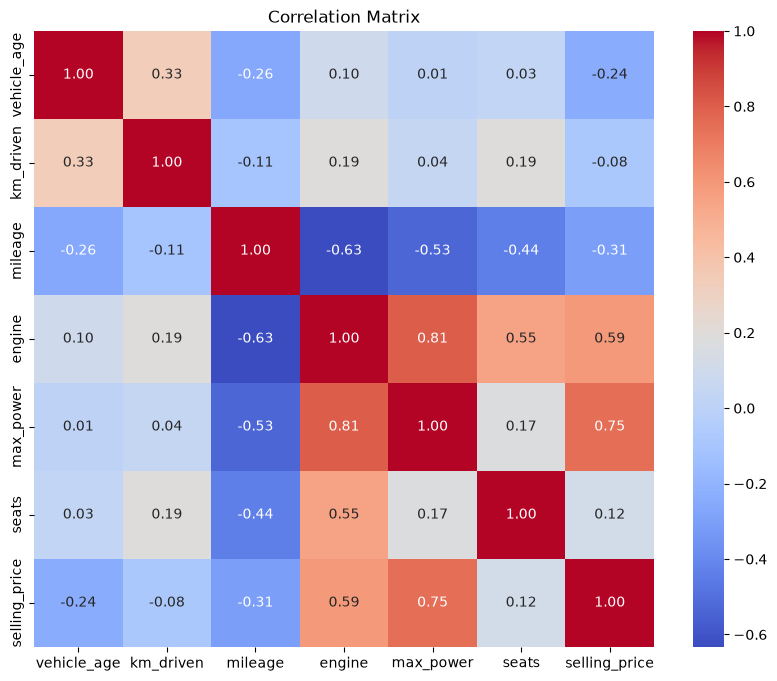

In [19]:
plt.figure(figsize=(10, 8))

corr = df[
    [
        "vehicle_age",
        "km_driven",
        "mileage",
        "engine",
        "max_power",
        "seats",
        "selling_price"
    ]
].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Matrix")
plt.show()

In [20]:
print("Unique car names:", df["car_name"].nunique())
print("Unique brands:", df["brand"].nunique())
print("Unique models:", df["model"].nunique())

Unique car names: 121
Unique brands: 32
Unique models: 120


In [21]:
print("Duplicate car_name/model combinations:")
print(
    df[["car_name", "brand", "model"]]
    .drop_duplicates()
    .head(20)
)

Duplicate car_name/model combinations:
                 car_name          brand        model
0             Maruti Alto         Maruti         Alto
1           Hyundai Grand        Hyundai        Grand
2             Hyundai i20        Hyundai          i20
4           Ford Ecosport           Ford     Ecosport
5          Maruti Wagon R         Maruti      Wagon R
6             Hyundai i10        Hyundai          i10
8           Hyundai Venue        Hyundai        Venue
9            Maruti Swift         Maruti        Swift
10          Hyundai Verna        Hyundai        Verna
11         Renault Duster        Renault       Duster
12            Mini Cooper           Mini       Cooper
13            Maruti Ciaz         Maruti         Ciaz
15  Mercedes-Benz C-Class  Mercedes-Benz      C-Class
17          Toyota Innova         Toyota       Innova
18          Maruti Baleno         Maruti       Baleno
19     Maruti Swift Dzire         Maruti  Swift Dzire
20       Volkswagen Vento     Volkswagen   

In [22]:
df.groupby("model")["brand"].nunique().sort_values(ascending=False).head(20)

model
MUX        2
3          1
6          1
5          1
A4         1
A6         1
A8         1
7          1
Altroz     1
Alturas    1
Amaze      1
Aspire     1
Aura       1
Baleno     1
Bolero     1
C          1
C-Class    1
CLS        1
CR         1
CR-V       1
Name: brand, dtype: int64

In [23]:
model_brand_counts = (
    df.groupby("model")["brand"]
    .nunique()
    .sort_values(ascending=False)
)

model_brand_counts[model_brand_counts > 1]

model
MUX    2
Name: brand, dtype: int64

In [24]:
df[df["model"].isin(
    model_brand_counts[model_brand_counts > 1].index
)][["car_name", "brand", "model", "selling_price"]].sort_values("model")

,car_name,brand,model,selling_price
3553,ISUZU MUX,ISUZU,MUX,1895000
12564,Isuzu MUX,Isuzu,MUX,2300000
14780,ISUZU MUX,ISUZU,MUX,1900000


In [25]:
print(
    "Car names mapped to multiple brands:",
    df.groupby("car_name")["brand"].nunique().gt(1).sum()
)

print(
    "Car names mapped to multiple models:",
    df.groupby("car_name")["model"].nunique().gt(1).sum()
)

Car names mapped to multiple brands: 0
Car names mapped to multiple models: 0
